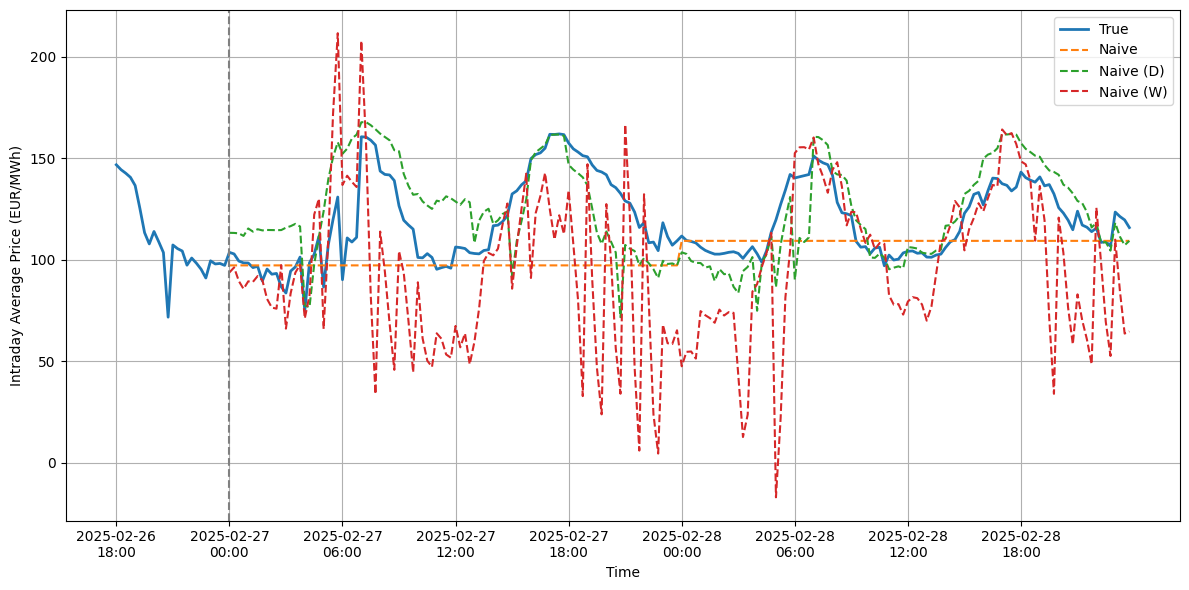

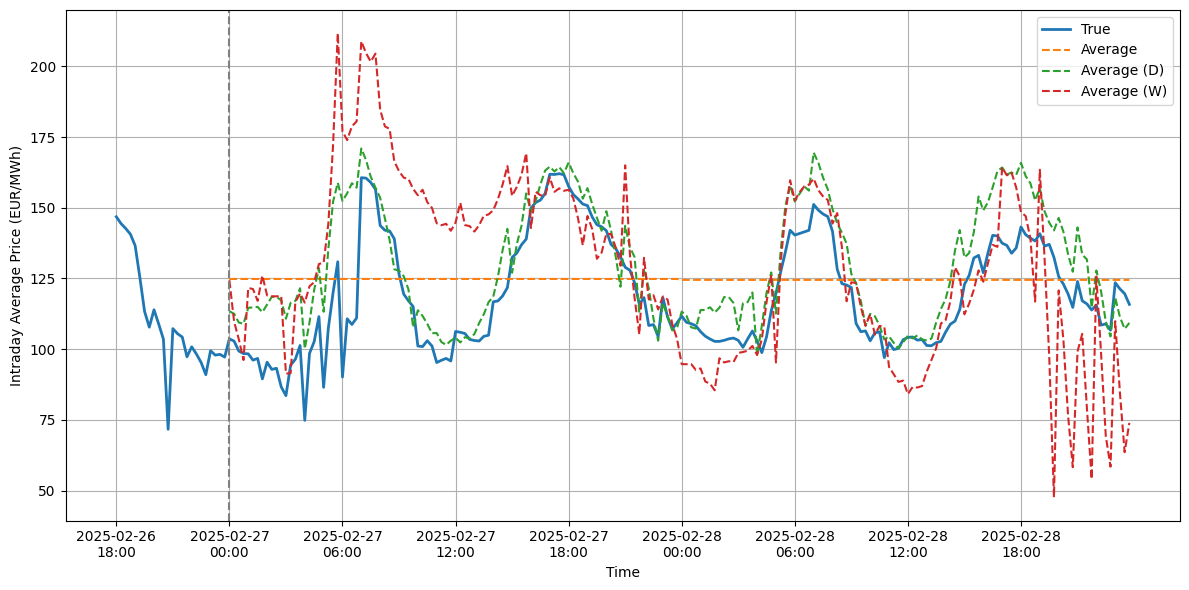

In [7]:
import os
import pandas as pd

from utils import RESULTS_DIR, INTERIM_DATA_DIR

TAB_ID_DIR = os.path.join(RESULTS_DIR, "TAB ID MAE Select")
TS_ID_DIR = os.path.join(RESULTS_DIR, "TS ID MAE Select")

naive = pd.read_csv(os.path.join(TS_ID_DIR, "Naive"), index_col=0, parse_dates=True)
naive_d = pd.read_csv(os.path.join(TS_ID_DIR, "SeasonalNaive"), index_col=0, parse_dates=True)
naive_w = pd.read_csv(os.path.join(TS_ID_DIR, "SeasonalNaive_2"), index_col=0, parse_dates=True)
avg = pd.read_csv(os.path.join(TS_ID_DIR, "Average"), index_col=0, parse_dates=True)
avg_d = pd.read_csv(os.path.join(TS_ID_DIR, "SeasonalAverage"), index_col=0, parse_dates=True)
avg_w = pd.read_csv(os.path.join(TS_ID_DIR, "SeasonalAverage_2"), index_col=0, parse_dates=True)
true_values = pd.read_csv(os.path.join(INTERIM_DATA_DIR, "data.csv"), index_col=0, parse_dates=True)

true_values.index = true_values.index.tz_convert(None)

true_values_filtered = true_values[
    (true_values.index >= "2025-02-26 18:00:00") & (true_values.index < "2025-03-01")
]
true_prices = true_values_filtered[["ID Weighted average of the prices (EUR/MWh)"]].copy()

forecast_start = pd.Timestamp("2025-02-27")
forecast_index = pd.date_range(start=forecast_start, periods=24 * 4 * 2, freq="15min")

def last_two_days(df):
    return [x for x in df.values[-24 * 4 * 2:]]

naive_df = pd.DataFrame({
    "timestamp": forecast_index,
    "Naive": last_two_days(naive),
    "Naive (D)": last_two_days(naive_d),
    "Naive (W)": last_two_days(naive_w)
})

average_df = pd.DataFrame({
    "timestamp": forecast_index,
    "Average": last_two_days(avg),
    "Average (D)": last_two_days(avg_d),
    "Average (W)": last_two_days(avg_w)
})

combined_naive = pd.merge(true_prices, naive_df, on="timestamp", how="outer")
combined_avg = pd.merge(true_prices, average_df, on="timestamp", how="outer")

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(combined_naive.index, combined_naive["ID Weighted average of the prices (EUR/MWh)"], label="True", linewidth=2)
plt.plot(combined_naive.index, combined_naive["Naive"], label="Naive", linestyle="--")
plt.plot(combined_naive.index, combined_naive["Naive (D)"], label="Naive (D)", linestyle="--")
plt.plot(combined_naive.index, combined_naive["Naive (W)"], label="Naive (W)", linestyle="--")
plt.axvline(x=24, color="grey", linestyle="--")
plt.xlabel("Time")
plt.xticks(ticks=combined_naive.index[::24], labels=true_prices.index[::24].strftime("%Y-%m-%d\n%H:%M"))
plt.ylabel("Intraday Average Price (EUR/MWh)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("intra_day_naive.png", dpi=600, bbox_inches="tight")
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(combined_avg.index, combined_avg["ID Weighted average of the prices (EUR/MWh)"], label="True", linewidth=2)
plt.plot(combined_avg.index, combined_avg["Average"], label="Average", linestyle="--")
plt.plot(combined_avg.index, combined_avg["Average (D)"], label="Average (D)", linestyle="--")
plt.plot(combined_avg.index, combined_avg["Average (W)"], label="Average (W)", linestyle="--")
plt.axvline(x=24, color="grey", linestyle="--")
plt.xlabel("Time")
plt.xticks(ticks=combined_naive.index[::24], labels=true_prices.index[::24].strftime("%Y-%m-%d\n%H:%M"))
plt.ylabel("Intraday Average Price (EUR/MWh)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("intra_day_average.png", dpi=600, bbox_inches="tight")
plt.show()

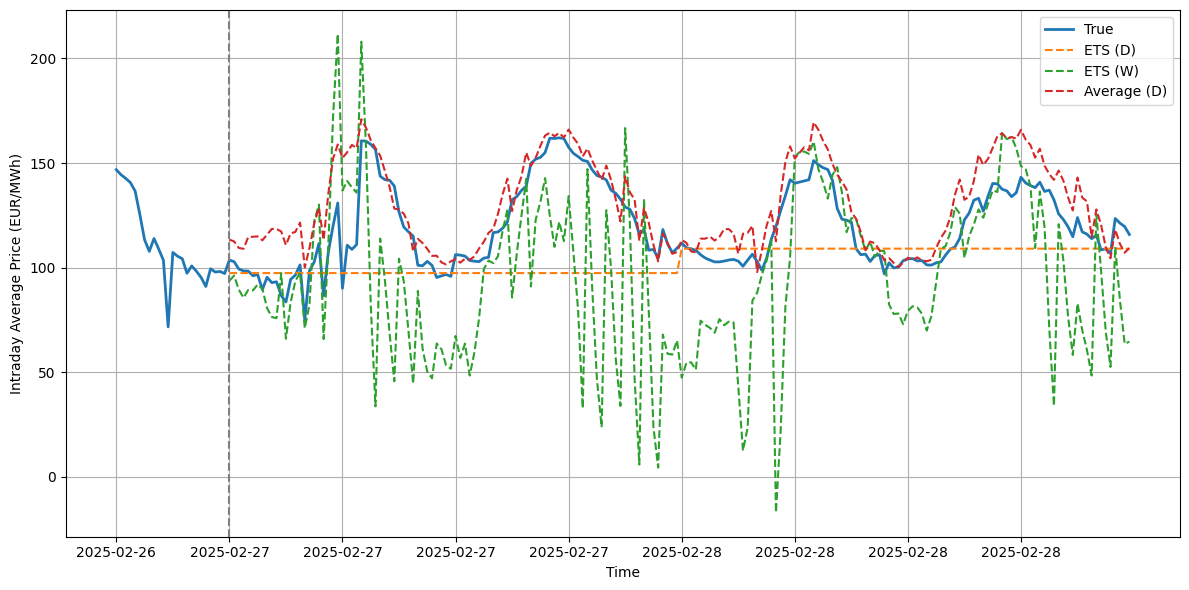

In [8]:
ets_d = pd.read_csv(os.path.join(TS_ID_DIR, "AutoETS"), index_col=0, parse_dates=True)
ets_w = pd.read_csv(os.path.join(TS_ID_DIR, "AutoETS_2"), index_col=0, parse_dates=True)

stats_df = pd.DataFrame({
    "timestamp": forecast_index,
    "ETS (D)": last_two_days(ets_d),
    "ETS (W)": last_two_days(ets_w),
})

combined_stats = pd.merge(true_prices, stats_df, on="timestamp", how="outer")

plt.figure(figsize=(12, 6))
plt.plot(combined_stats.index, combined_stats["ID Weighted average of the prices (EUR/MWh)"], label="True", linewidth=2)
plt.plot(combined_stats.index, combined_stats["ETS (D)"], label="ETS (D)", linestyle="--")
plt.plot(combined_stats.index, combined_stats["ETS (W)"], label="ETS (W)", linestyle="--")
plt.plot(combined_avg.index, combined_avg["Average (D)"], label="Average (D)", linestyle="--")
plt.axvline(x=24, color="grey", linestyle="--")
plt.xlabel("Time")
plt.xticks(ticks=combined_stats.index[::24], labels=true_prices.index[::24].strftime("%Y-%m-%d"))
plt.ylabel("Intraday Average Price (EUR/MWh)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("intra_day_stats.png", dpi=600, bbox_inches="tight")
plt.show()

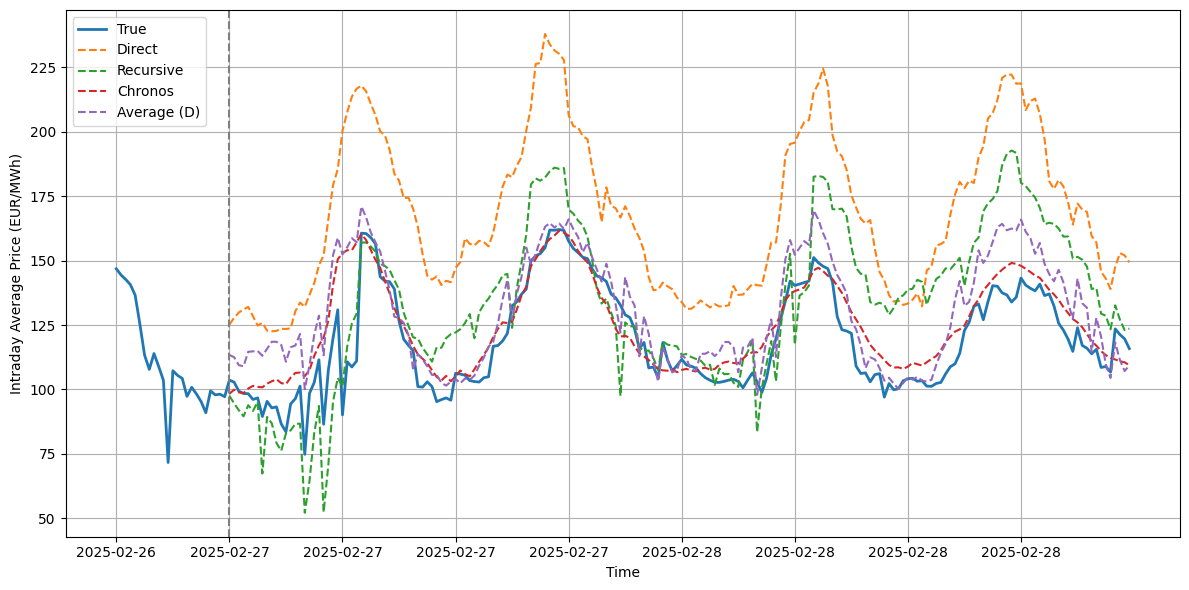

In [9]:
direct = pd.read_csv(os.path.join(TS_ID_DIR, "DirectTabular"), index_col=0, parse_dates=True)
recursive = pd.read_csv(os.path.join(TS_ID_DIR, "RecursiveTabular"), index_col=0, parse_dates=True)
chronos = pd.read_csv(os.path.join(TS_ID_DIR, "Chronos[autogluon__chronos-bolt-small]"), index_col=0, parse_dates=True)

ml_df = pd.DataFrame({
    "timestamp": forecast_index,
    "Direct": last_two_days(direct),
    "Recursive": last_two_days(recursive),
    "Chronos": last_two_days(chronos),
})

combined_ml = pd.merge(true_prices, ml_df, on="timestamp", how="outer")

plt.figure(figsize=(12, 6))
plt.plot(combined_ml.index, combined_ml["ID Weighted average of the prices (EUR/MWh)"], label="True", linewidth=2)
plt.plot(combined_ml.index, combined_ml["Direct"], label="Direct", linestyle="--")
plt.plot(combined_ml.index, combined_ml["Recursive"], label="Recursive", linestyle="--")
plt.plot(combined_ml.index, combined_ml["Chronos"], label="Chronos", linestyle="--")
plt.plot(combined_avg.index, combined_avg["Average (D)"], label="Average (D)", linestyle="--")
plt.axvline(x=24, color="grey", linestyle="--")
plt.xlabel("Time")
plt.xticks(ticks=combined_ml.index[::24], labels=true_prices.index[::24].strftime("%Y-%m-%d"))
plt.ylabel("Intraday Average Price (EUR/MWh)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("intra_day_ml.png", dpi=600, bbox_inches="tight")
plt.show()

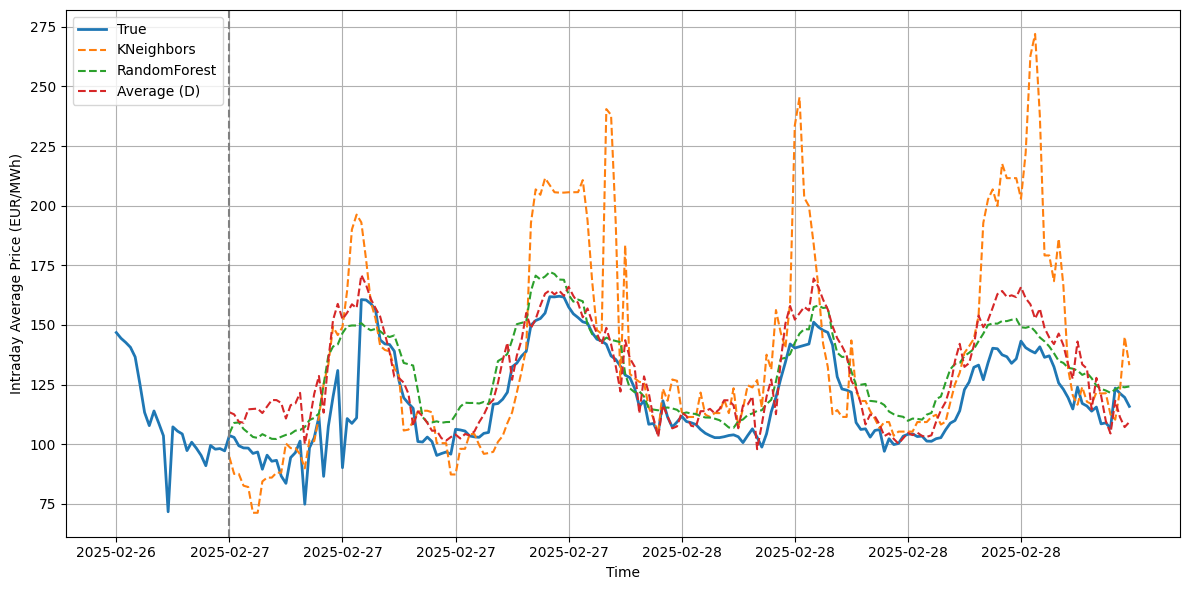

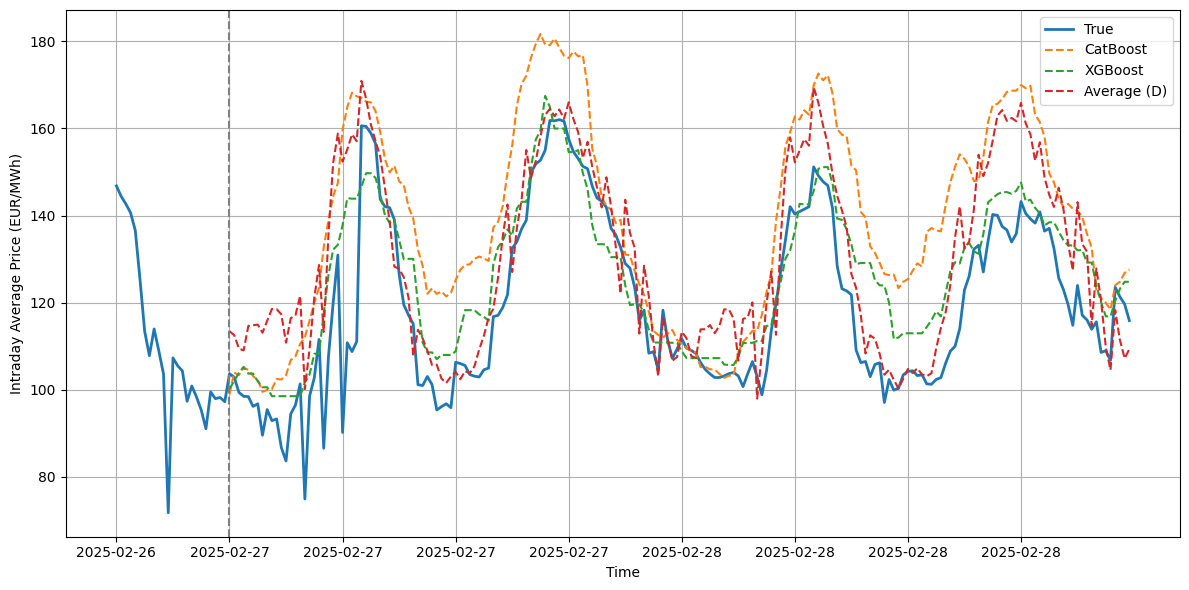

In [10]:
knn = pd.read_csv(os.path.join(TAB_ID_DIR, "KNeighbors"), index_col=0, parse_dates=True)
rf = pd.read_csv(os.path.join(TAB_ID_DIR, "RandomForest"), index_col=0, parse_dates=True)
cat = pd.read_csv(os.path.join(TAB_ID_DIR, "CatBoost"), index_col=0, parse_dates=True)
xg = pd.read_csv(os.path.join(TAB_ID_DIR, "XGBoost"), index_col=0, parse_dates=True)

tab_df = pd.DataFrame({
    "timestamp": forecast_index,
    "KNeighbors": last_two_days(knn),
    "RandomForest": last_two_days(rf),
    "CatBoost": last_two_days(cat),
    "XGBoost": last_two_days(xg),
})

combined_tab = pd.merge(true_prices, tab_df, on="timestamp", how="outer")

plt.figure(figsize=(12, 6))
plt.plot(combined_tab.index, combined_tab["ID Weighted average of the prices (EUR/MWh)"], label="True", linewidth=2)
plt.plot(combined_tab.index, combined_tab["KNeighbors"], label="KNeighbors", linestyle="--")
plt.plot(combined_tab.index, combined_tab["RandomForest"], label="RandomForest", linestyle="--")
plt.plot(combined_avg.index, combined_avg["Average (D)"], label="Average (D)", linestyle="--")
plt.axvline(x=24, color="grey", linestyle="--")
plt.xlabel("Time")
plt.xticks(ticks=combined_tab.index[::24], labels=true_prices.index[::24].strftime("%Y-%m-%d"))
plt.ylabel("Intraday Average Price (EUR/MWh)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("intra_day_tab1.png", dpi=600, bbox_inches="tight")
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(combined_tab.index, combined_tab["ID Weighted average of the prices (EUR/MWh)"], label="True", linewidth=2)
plt.plot(combined_tab.index, combined_tab["CatBoost"], label="CatBoost", linestyle="--")
plt.plot(combined_tab.index, combined_tab["XGBoost"], label="XGBoost", linestyle="--")
plt.plot(combined_avg.index, combined_avg["Average (D)"], label="Average (D)", linestyle="--")
plt.axvline(x=24, color="grey", linestyle="--")
plt.xlabel("Time")
plt.xticks(ticks=combined_tab.index[::24], labels=true_prices.index[::24].strftime("%Y-%m-%d"))
plt.ylabel("Intraday Average Price (EUR/MWh)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("intra_day_tab2.png", dpi=600, bbox_inches="tight")
plt.show()

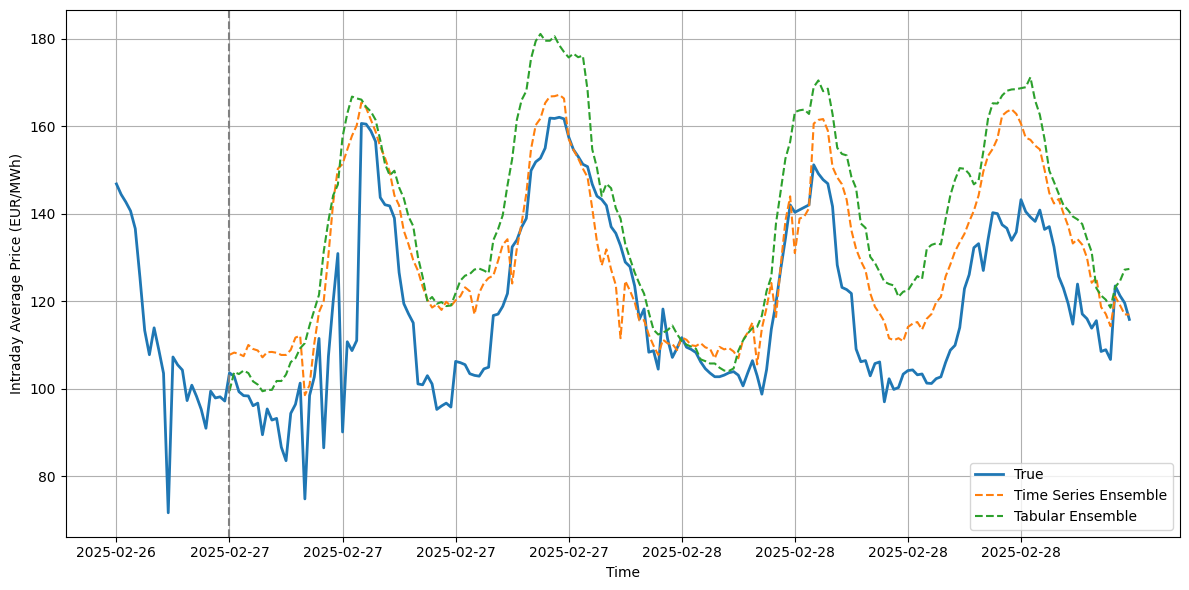

In [11]:
tse = pd.read_csv(os.path.join(TS_ID_DIR, "WeightedEnsemble"), index_col=0, parse_dates=True)
tabe = pd.read_csv(os.path.join(TAB_ID_DIR, "WeightedEnsemble_L2"), index_col=0, parse_dates=True)

ens_df = pd.DataFrame({
    "timestamp": forecast_index,
    "Time Series Ensemble": last_two_days(tse),
    "Tabular Ensemble": last_two_days(tabe),
})

combined_ens = pd.merge(true_prices, ens_df, on="timestamp", how="outer")

plt.figure(figsize=(12, 6))
plt.plot(combined_ens.index, combined_ens["ID Weighted average of the prices (EUR/MWh)"], label="True", linewidth=2)
plt.plot(combined_ens.index, combined_ens["Time Series Ensemble"], label="Time Series Ensemble", linestyle="--")
plt.plot(combined_ens.index, combined_ens["Tabular Ensemble"], label="Tabular Ensemble", linestyle="--")
plt.axvline(x=24, color="grey", linestyle="--")
plt.xlabel("Time")
plt.xticks(ticks=combined_ens.index[::24], labels=true_prices.index[::24].strftime("%Y-%m-%d"))
plt.ylabel("Intraday Average Price (EUR/MWh)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("intra_day_ens.png", dpi=600, bbox_inches="tight")
plt.show()